<a href="https://colab.research.google.com/github/faat-prasojo/Pembelajaran_Mesin_2026/blob/main/Pertemuan%2009/Tugas_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi SMS spam dengan Multinomial Naive Bayes (spam.csv)

Dua model dibandingkan dengan data, split, dan classifier yang sama. Satu-satunya yang berbeda adalah cara mengubah teks menjadi angka:

1. `CountVectorizer(stop_words="english")` + MultinomialNB
2. `TfidfVectorizer(stop_words="english")` + MultinomialNB


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

# Upload spam.csv jika belum ada (khusus Google Colab)
if not os.path.exists("spam.csv"):
    from google.colab import files
    files.upload()

# File ini berenkoding latin-1 dan punya 3 kolom tambahan yang hampir kosong
df = pd.read_csv("spam.csv", encoding="latin-1")
print("Bentuk awal:", df.shape)
print("Isi kolom tambahan (non-null):", df.iloc[:, 2:].notna().sum().tolist())

df = df[["v1", "v2"]]
df.columns = ["label", "text"]
y = (df["label"] == "spam").astype(int)    # spam = 1 (kelas positif), ham = 0
X = df["text"]

print("\nMissing values:", df.isna().sum().sum())
print("Teks duplikat:", df["text"].duplicated().sum())
print(df["label"].value_counts())
df.head()

Bentuk awal: (5572, 5)
Isi kolom tambahan (non-null): [50, 12, 6]

Missing values: 0
Teks duplikat: 403
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Eksplorasi data

Datanya tidak seimbang: ham jauh lebih banyak daripada spam. Karena itu akurasi saja tidak cukup untuk menilai model. Model yang menebak "ham" untuk semua pesan sudah mendapat akurasi sekitar 86,6%. Evaluasi di bawah menekankan precision, recall, dan F1 untuk kelas spam.

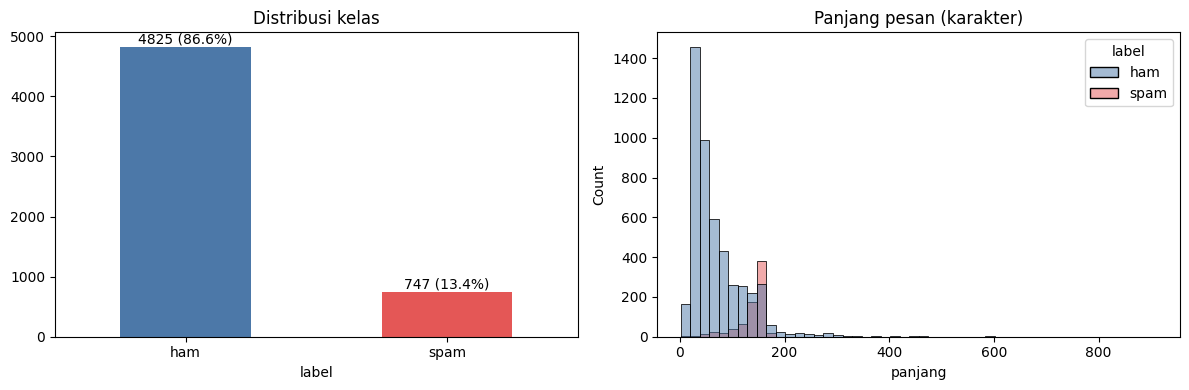

Akurasi baseline jika semua ditebak ham: 0.8659


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df["label"].value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], rot=0)
ax[0].set_title("Distribusi kelas")
for i, v in enumerate(df["label"].value_counts()):
    ax[0].text(i, v + 50, f"{v} ({v/len(df):.1%})", ha="center")

df["panjang"] = df["text"].str.len()
sns.histplot(data=df, x="panjang", hue="label", bins=50, ax=ax[1],
             palette={"ham": "#4C78A8", "spam": "#E45756"})
ax[1].set_title("Panjang pesan (karakter)")
plt.tight_layout(); plt.show()

print("Akurasi baseline jika semua ditebak ham:", round((y == 0).mean(), 4))

## Split data

Split 80/20 dengan stratifikasi supaya proporsi spam sama di train dan test. Vectorizer dibungkus `Pipeline` bersama classifier, jadi vocabulary dan nilai IDF hanya dipelajari dari data training.

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", len(Xtr), "| Test:", len(Xte))
print("Proporsi spam di train:", round(ytr.mean(), 4), "| di test:", round(yte.mean(), 4))

def evaluasi(nama, model):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    hasil = {
        "Model": nama,
        "Accuracy": accuracy_score(yte, pred),
        "Precision (spam)": precision_score(yte, pred),
        "Recall (spam)": recall_score(yte, pred),
        "F1 (spam)": f1_score(yte, pred),
        "ROC AUC": roc_auc_score(yte, proba),
    }
    print(f"=== {nama} ===")
    print(classification_report(yte, pred, target_names=["ham", "spam"], digits=4))
    return hasil, pred, proba

Train: 4457 | Test: 1115
Proporsi spam di train: 0.1342 | di test: 0.1336


## Model 1: CountVectorizer + MultinomialNB

`CountVectorizer` menghitung berapa kali tiap kata muncul dalam sebuah pesan. Stop words bahasa Inggris dibuang lewat `stop_words="english"`.

Ukuran vocabulary: 7440
=== CountVectorizer ===
              precision    recall  f1-score   support

         ham     0.9877    0.9938    0.9907       966
        spam     0.9580    0.9195    0.9384       149

    accuracy                         0.9839      1115
   macro avg     0.9728    0.9566    0.9645      1115
weighted avg     0.9837    0.9839    0.9837      1115



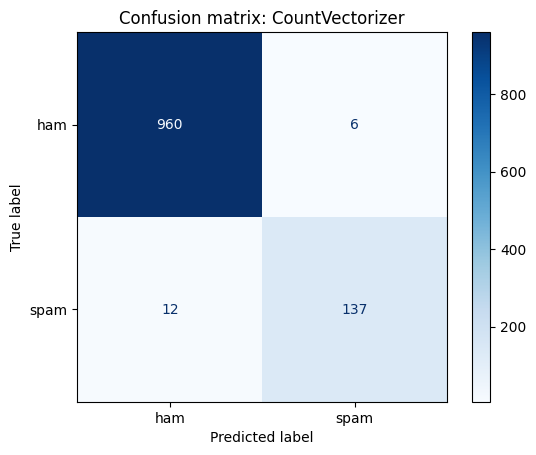

In [ ]:
model_count = make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB())
model_count.fit(Xtr, ytr)

print("Ukuran vocabulary:", len(model_count[0].vocabulary_))
res_count, pred_count, proba_count = evaluasi("CountVectorizer", model_count)

ConfusionMatrixDisplay.from_predictions(yte, pred_count, display_labels=["ham", "spam"], cmap="Blues")
plt.title("Confusion matrix: CountVectorizer"); plt.show()

In [ ]:
# Kata yang paling mendorong prediksi spam (selisih log probabilitas spam vs ham)
vocab = np.array(model_count[0].get_feature_names_out())
nb = model_count[1]
selisih = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top = pd.DataFrame({"kata": vocab[np.argsort(selisih)[::-1][:15]],
                    "log_rasio": np.sort(selisih)[::-1][:15].round(2)})
top

,kata,log_rasio
0,claim,5.26
1,prize,4.93
2,150p,4.71
3,tone,4.56
4,18,4.44
5,cs,4.39
6,guaranteed,4.34
7,500,4.34
8,1000,4.23
9,uk,4.17


## Model 2: TF-IDF + MultinomialNB

`TfidfVectorizer` memberi bobot lebih rendah pada kata yang muncul di banyak pesan dan lebih tinggi pada kata yang jarang. Defaultnya juga menormalisasi tiap pesan dengan norma L2, jadi nilai fiturnya pecahan di bawah 1. Pengaturan lain sama persis dengan Model 1.

Ukuran vocabulary: 7440
=== TF-IDF ===
              precision    recall  f1-score   support

         ham     0.9650    1.0000    0.9822       966
        spam     1.0000    0.7651    0.8669       149

    accuracy                         0.9686      1115
   macro avg     0.9825    0.8826    0.9246      1115
weighted avg     0.9697    0.9686    0.9668      1115



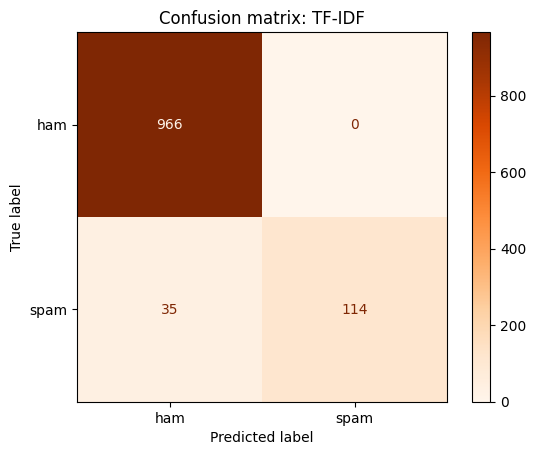

In [ ]:
model_tfidf = make_pipeline(TfidfVectorizer(stop_words="english"), MultinomialNB())
model_tfidf.fit(Xtr, ytr)

print("Ukuran vocabulary:", len(model_tfidf[0].vocabulary_))
res_tfidf, pred_tfidf, proba_tfidf = evaluasi("TF-IDF", model_tfidf)

ConfusionMatrixDisplay.from_predictions(yte, pred_tfidf, display_labels=["ham", "spam"], cmap="Oranges")
plt.title("Confusion matrix: TF-IDF"); plt.show()

## Perbandingan kedua model

Semua metrik dihitung pada test set yang sama (1.115 pesan, 149 di antaranya spam).

,Accuracy,Precision (spam),Recall (spam),F1 (spam),ROC AUC
Model,,,,,
CountVectorizer,0.9839,0.958,0.9195,0.9384,0.9896
TF-IDF,0.9686,1.000,0.7651,0.8669,0.9895


CountVectorizer  ham salah ditandai spam (FP) =   6 | spam lolos (FN) =  12
TF-IDF           ham salah ditandai spam (FP) =   0 | spam lolos (FN) =  35


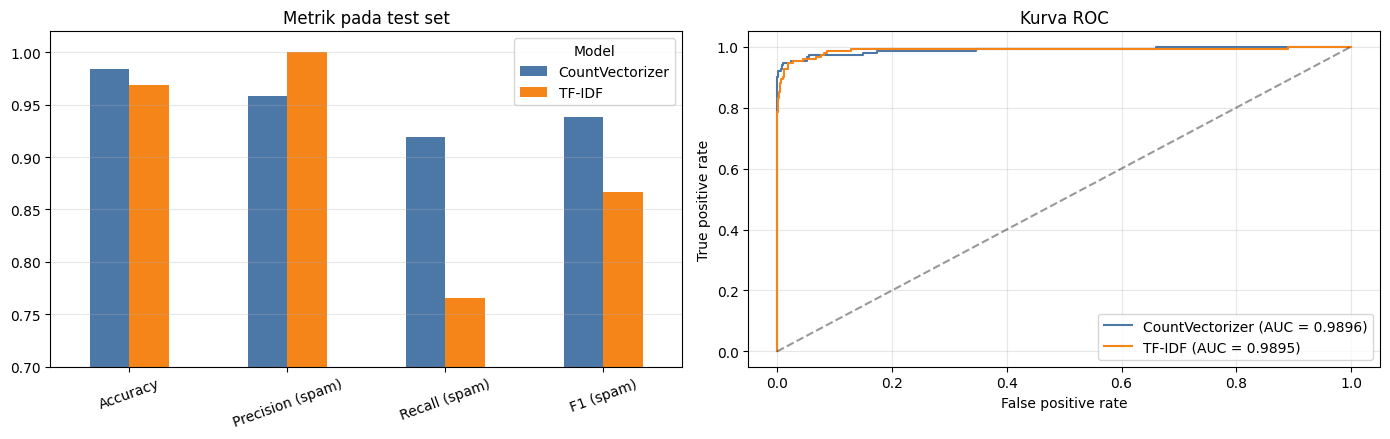

In [ ]:
tabel = pd.DataFrame([res_count, res_tfidf]).set_index("Model")
display(tabel.round(4))

# Selisih error: berapa pesan yang salah diprediksi
for nama, pred in [("CountVectorizer", pred_count), ("TF-IDF", pred_tfidf)]:
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    print(f"{nama:16s} ham salah ditandai spam (FP) = {fp:3d} | spam lolos (FN) = {fn:3d}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tabel.drop(columns="ROC AUC").T.plot.bar(ax=ax[0], rot=20, color=["#4C78A8", "#F58518"])
ax[0].set_ylim(0.7, 1.02); ax[0].set_title("Metrik pada test set"); ax[0].grid(axis="y", alpha=.3)

for nama, proba, warna in [("CountVectorizer", proba_count, "#4C78A8"), ("TF-IDF", proba_tfidf, "#F58518")]:
    fpr, tpr, _ = roc_curve(yte, proba)
    ax[1].plot(fpr, tpr, label=f"{nama} (AUC = {roc_auc_score(yte, proba):.4f})", color=warna)
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("Kurva ROC"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Uji kestabilan dengan cross-validation

Satu split bisa kebetulan menguntungkan salah satu model. Di sini dipakai stratified 5-fold yang diulang 3 kali (15 evaluasi per model) pada seluruh data.

In [ ]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)
metrik = ["accuracy", "precision", "recall", "f1"]
baris = []
for nama, vec in [("CountVectorizer", CountVectorizer(stop_words="english")),
                  ("TF-IDF", TfidfVectorizer(stop_words="english"))]:
    cv = cross_validate(make_pipeline(vec, MultinomialNB()), X, y, cv=rcv, scoring=metrik)
    r = {"Model": nama}
    for m in metrik:
        r[f"{m} mean"] = cv[f"test_{m}"].mean()
        r[f"{m} std"] = cv[f"test_{m}"].std()
    baris.append(r)
cv_tabel = pd.DataFrame(baris).set_index("Model")
display(cv_tabel.round(4))

,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
Model,,,,,,,,
CountVectorizer,0.9857,0.0028,0.9602,0.0124,0.9322,0.0184,0.9458,0.0108
TF-IDF,0.9722,0.0029,0.9989,0.0028,0.7934,0.0229,0.8842,0.0137


## Pengecekan tambahan: pengaruh smoothing alpha

Kedua model di atas memakai `alpha=1.0` (default). Pada TF-IDF, nilai fitur berupa pecahan kecil, sehingga smoothing alpha=1 bisa terlalu besar relatif terhadap total bobot tiap kelas. Sel ini menguji apakah selisih kedua model tetap ada ketika alpha diubah.

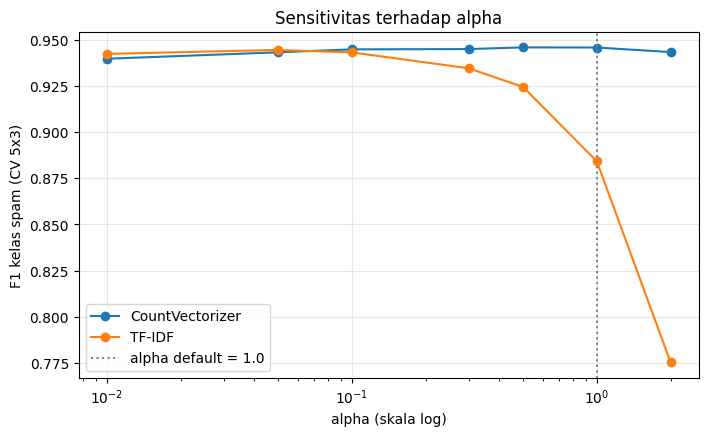

,CountVectorizer,TF-IDF
0.01,0.9398,0.9424
0.05,0.9433,0.9445
0.10,0.9448,0.9432
0.30,0.9450,0.9346
0.50,0.9459,0.9245
1.00,0.9458,0.8842
2.00,0.9434,0.7753


In [ ]:
alphas = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0]
hasil_alpha = {"CountVectorizer": [], "TF-IDF": []}
for a in alphas:
    for nama, vec_cls in [("CountVectorizer", CountVectorizer), ("TF-IDF", TfidfVectorizer)]:
        cv = cross_validate(make_pipeline(vec_cls(stop_words="english"), MultinomialNB(alpha=a)),
                            X, y, cv=rcv, scoring=["f1"])
        hasil_alpha[nama].append(cv["test_f1"].mean())

plt.figure(figsize=(8, 4.5))
for nama, vals in hasil_alpha.items():
    plt.plot(alphas, vals, marker="o", label=nama)
plt.xscale("log"); plt.xlabel("alpha (skala log)"); plt.ylabel("F1 kelas spam (CV 5x3)")
plt.axvline(1.0, color="gray", ls=":", label="alpha default = 1.0")
plt.title("Sensitivitas terhadap alpha"); plt.grid(alpha=.3); plt.legend(); plt.show()

pd.DataFrame(hasil_alpha, index=alphas).round(4)

## Kesimpulan

Dengan pengaturan yang diminta soal (stop_words aktif, parameter lain default, alpha=1), **CountVectorizer adalah fitur terbaik** untuk spam.csv.

Pada test set, CountVectorizer mendapat accuracy 98,39% dan F1 spam 0,938, sedangkan TF-IDF mendapat 96,86% dan 0,867. Perbedaan terbesar ada di recall spam: 91,9% untuk CountVectorizer dan 76,5% untuk TF-IDF. TF-IDF melewatkan 35 pesan spam, CountVectorizer 12. TF-IDF memang tidak pernah salah menandai pesan ham (precision 100%), tetapi harganya spam yang lolos hampir tiga kali lebih banyak. Hasil cross-validation 5x3 mengarah ke sisi yang sama (accuracy 98,57% vs 97,22%, F1 0,946 vs 0,884), dan jaraknya jauh lebih besar dari standar deviasi antar fold.

Ada satu catatan penting. ROC AUC kedua model hampir sama (0,9896 vs 0,9895), artinya kemampuan mengurutkan spam di atas ham sebenarnya setara. Selisihnya muncul pada titik keputusan, dan analisis alpha menunjukkan penyebabnya: ketika alpha diturunkan ke 0,05 sampai 0,1, TF-IDF mengejar CountVectorizer dan selisih F1 hilang. Jadi kemenangan CountVectorizer berlaku untuk konfigurasi default, bukan untuk semua konfigurasi. Jika alpha boleh dituning, kedua fitur layak dianggap sama baik, dan CountVectorizer tetap lebih aman karena tidak peka terhadap pilihan alpha.

Keterbatasan: 403 teks duplikat masih ada di dataset, sehingga sebagian pesan test mungkin juga muncul di data training dan angka sedikit lebih optimis. Pada kelas spam yang hanya 149 sampel di test set, selisih 1 pesan setara 0,7 poin recall.